<a href="https://colab.research.google.com/github/Samarthkumbhar99/Machine-Leaning/blob/main/XGBoost_AgaBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Name : Samarth Bajirao Kumbhar
# Roll No : A31     class : TY-A31
# PRN : 2425000179




In [ ]:
!pip install xgboost

First five rows of the Iris dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Dataset shape: (150, 5)

Input variables X:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5          

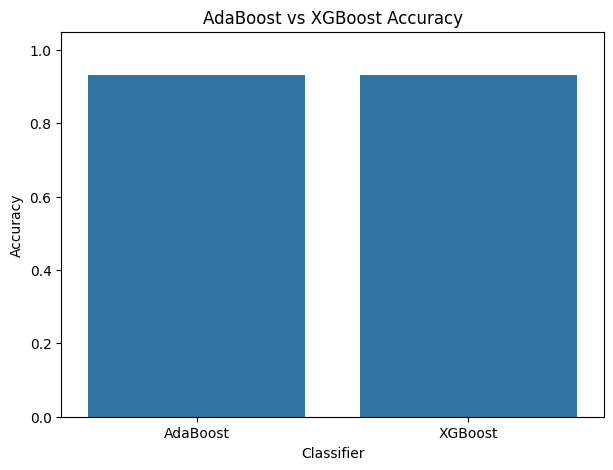

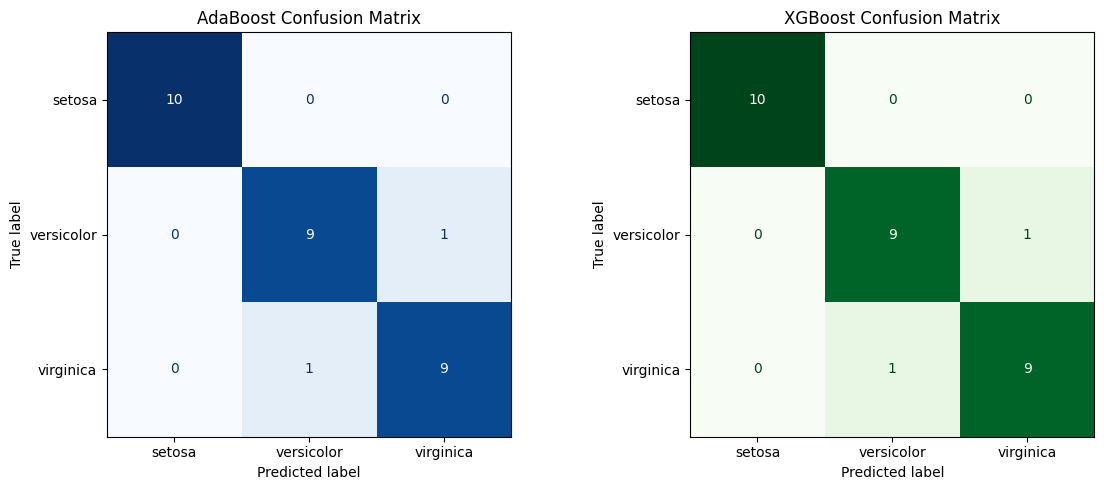

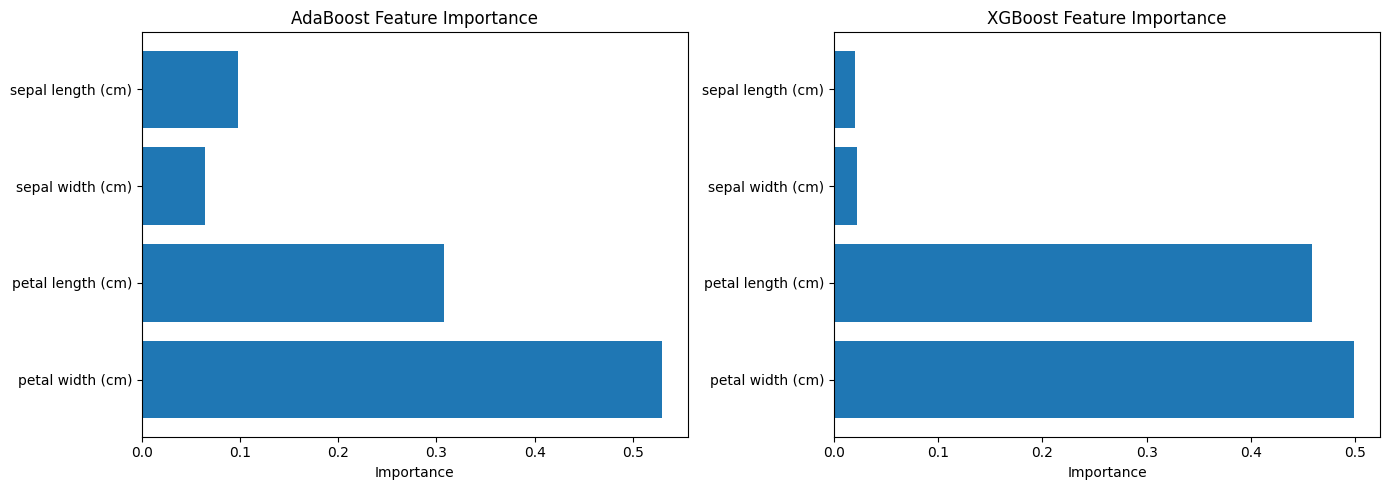


========== FINAL RESULT ==========
Both classifiers achieved the same test accuracy.

Assignment 11 completed successfully!


In [ ]:

# Assignment 11 – XGBoost and AdaBoost

# 1. Import the basic libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

# Install XGBoost in Google Colab if required
# Uncomment the next line if XGBoost is not installed:
# !pip install xgboost


# 2. Load the Iris dataset

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["target"] = iris.target

print("First five rows of the Iris dataset:")
print(df.head())

print("\nDataset shape:", df.shape)


# 3. Figure out input variables X and output y

X = df.drop("target", axis=1)
y = df["target"]

print("\nInput variables X:")
print(X.head())

print("\nOutput variable y:")
print(y.head())

print("\nX shape:", X.shape)
print("y shape:", y.shape)


# 4. Perform the train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining and testing shapes:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


# 5. Train the model with AdaBoost Classifier

ada_model = AdaBoostClassifier(
    n_estimators=50,
    random_state=42
)

ada_model.fit(X_train, y_train)

print("\nAdaBoost model trained successfully.")


# 6. Test the model with AdaBoost Classifier

y_pred_ada = ada_model.predict(X_test)

ada_accuracy = accuracy_score(y_test, y_pred_ada)

print("\nAdaBoost Accuracy:", round(ada_accuracy, 4))

print("\nAdaBoost Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_ada,
        target_names=iris.target_names,
        zero_division=0
    )
)


# 7. Train the model with XGBoost Classifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("\nXGBoost model trained successfully.")


# 8. Test the model with XGBoost Classifier

y_pred_xgb = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("\nXGBoost Accuracy:", round(xgb_accuracy, 4))

print("\nXGBoost Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=iris.target_names,
        zero_division=0
    )
)


# 9. Compare both classifiers:
# Display classification reports and accuracy

print("\n========== MODEL COMPARISON ==========")

print("\nAdaBoost Accuracy:", round(ada_accuracy, 4))
print("XGBoost Accuracy:", round(xgb_accuracy, 4))

comparison = pd.DataFrame({
    "Classifier": ["AdaBoost", "XGBoost"],
    "Accuracy": [ada_accuracy, xgb_accuracy]
})

print("\nAccuracy Comparison:")
print(comparison)

# Plot accuracy comparison

plt.figure(figsize=(7, 5))

sns.barplot(
    data=comparison,
    x="Classifier",
    y="Accuracy"
)

plt.title("AdaBoost vs XGBoost Accuracy")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.show()


# 10. Visualize confusion matrices side-by-side

cm_ada = confusion_matrix(
    y_test,
    y_pred_ada,
    labels=[0, 1, 2]
)

cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb,
    labels=[0, 1, 2]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_ada,
    display_labels=iris.target_names
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

axes[0].set_title("AdaBoost Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=iris.target_names
).plot(
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)

axes[1].set_title("XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()


# 11. Visualize feature importance side-by-side

ada_importance = ada_model.feature_importances_
xgb_importance = xgb_model.feature_importances_

feature_names = X.columns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# AdaBoost feature importance

axes[0].barh(
    feature_names,
    ada_importance
)

axes[0].set_title("AdaBoost Feature Importance")
axes[0].set_xlabel("Importance")
axes[0].invert_yaxis()


# XGBoost feature importance

axes[1].barh(
    feature_names,
    xgb_importance
)

axes[1].set_title("XGBoost Feature Importance")
axes[1].set_xlabel("Importance")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


# Final comparison

print("\n========== FINAL RESULT ==========")

if ada_accuracy > xgb_accuracy:
    print("AdaBoost performed better on the test dataset.")
elif xgb_accuracy > ada_accuracy:
    print("XGBoost performed better on the test dataset.")
else:
    print("Both classifiers achieved the same test accuracy.")

print("\nAssignment 11 completed successfully!")
